# Figure 3, Panel F

Volcano plots showing differential gene expression (BAFinh vs Vehicle) at 1h, 6h, and 30h treatment

*Output: PanelF.pdf*

# Setup

In [1]:
#load packages
library(tidyverse)
library(ggrastr)
library(patchwork)
library(RColorBrewer)
library(here)
here::i_am("figures/Figure3/PanelF/PanelF.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank()))
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         RColorBrewer_1.1-3 patchwork_1.3.0    ggrastr_1.0.2     
 [5] lubridate_1.9.4    forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4       
 [9] purrr_1.0.2        readr_2.1.5        tidyr_1.3.1        tibble_3.2.1      
[13] ggplot2_3.5.2      tidyverse_2.0.0   

loaded 

# Load data

In [2]:
#load differential gene expression results for BAFinh vs Vehicle at 1h, 6h, and 30h of treatment
brm_1h <- read.delim(
    here(
        "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", 
        "BAFinh_1h_DEGs.tsv"
    ),
        sep = "\t"
)

brm_6h <- read.delim(
    here(
        "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", 
        "BAFinh_6h_DEGs.tsv"
    ),
        sep = "\t"
)

brm_30h <- read.delim(
    here(
        "inputs", "DEGs", "GM12878",
        "BRM_30h_DEGs.tsv"
    ),
    sep = "\t"
)

In [4]:
#function to draw volcano plots
volcano <- function(df){
    n <- df$change %>% table()
    plot <- ggplot(df, aes(x=log2FoldChange,y=-log10(padj))) +
    theme_bw() + theme(panel.grid=element_blank()) + 
    geom_vline(xintercept=c(-log2(1.5), log2(1.5)), linetype=2) +
    geom_hline(yintercept=-log10(.05), linetype=2) + 
    rasterize(geom_point(aes(color=change), size=.25), dpi=300)+
    xlim(-max(abs(df$log2FoldChange)), max(abs(df$log2FoldChange))) +
    scale_color_manual(values=c("down"= brewer.pal(3, "Paired")[2],
                                "ns" = "#aaaaaa", 
                                "up"=brewer.pal(6, "Paired")[6])) +
    ggtitle(paste("Down:", n[1], "Up:", n[3]))

    return(plot)
    }
volc_1h <- suppressWarnings(volcano(brm_1h))
volc_6h <- suppressWarnings(volcano(brm_6h))
volc_30h <- suppressWarnings(volcano(brm_30h))

Warning message:
“Removed 244 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 244 rows containing missing values or values outside the scale range
(`geom_point()`).”


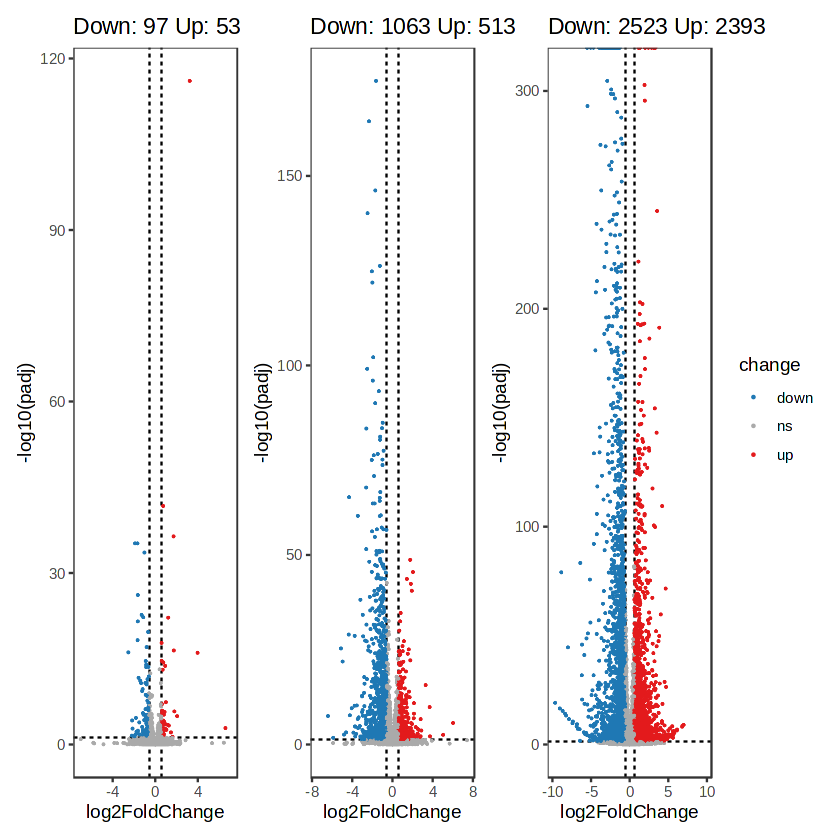

In [6]:
(volc_1h | volc_6h | volc_30h) +
    plot_layout(guides="collect")
ggsave("PanelF.pdf", height=3, width=9)